# 02 — Analyse en Composantes Principales (ACP)
### Projet M1 Informatique · Aide au diagnostic médical (Breast Cancer Wisconsin Diagnostic)

**Point de départ.** Le notebook 01 a montré deux choses :

1. les 30 variables ont des **échelles très différentes** → il faut une ACP **centrée-réduite** (ACP normée, sur la matrice de corrélation) ;
2. elles sont **très redondantes** (23 VIF > 10, rayon/périmètre/aire corrélés à 0,99) → beaucoup de colonnes racontent la même histoire. Quelques axes devraient suffire.

**Questions du sujet auxquelles ce notebook répond :**

- Combien d'axes faut-il pour conserver **90 à 95 %** de l'information ?
- Quelles variables **dominent l'axe 1** (cercle des corrélations) ?
- Que montre la projection des patientes, colorée bénin/malin ?

On suit **exactement** la démarche du cours :

| Étape | Calcul | Pourquoi ? |
|---|---|---|
| 1. Réduire | $Z = (X - \bar X)/s$ | Comparer des variables d'unités différentes |
| 2. Corrélation | $R = Z^\top Z/(n-1)$ | Décrire les variations communes |
| 3. Valeurs / vecteurs propres | $R u_k = \lambda_k u_k$, $u_k^\top u_k = 1$ | Trouver les directions de variance maximale |
| 4. Projeter | $F = Z U$ | Coordonnées des patientes sur les nouveaux axes |
| 5. Variance expliquée | $\lambda_k / \sum_j \lambda_j$ | Combien d'information chaque axe conserve |
| 6. Cercle des corrélations | $\operatorname{Corr}(Z_j, CP_k) = u_{jk}\sqrt{\lambda_k}$ | Interpréter les axes |
| 7. Choisir $k$ | Variance cumulée + validation | Réduire sans compromettre l'objectif |

> **Rappel essentiel.** L'ACP est **non supervisée** : elle ne regarde **jamais** le diagnostic pour construire ses axes. Le diagnostic ne sert ici qu'à **colorer** les graphiques, après coup.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse, Circle, Patch
from matplotlib.lines import Line2D
import seaborn as sns
from sklearn.metrics import roc_auc_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src")); sys.path.insert(0, str(ROOT / "notebooks"))
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)

import preprocessing as pp
import pca_analysis as pa
from _style import setup, PALETTE, COL_B, COL_M, FAMILY_COLORS
setup(); warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160, "display.float_format", "{:.4g}".format)

df, X, y = pp.load_clean_data(ROOT / "data" / "raw" / "data.csv")
print(f"{X.shape[0]} patientes × {X.shape[1]} variables ; {y.mean():.1%} de tumeurs malignes")

569 patientes × 30 variables ; 37.3% de tumeurs malignes


## 1. Centrer-réduire et construire la matrice de corrélation

On utilise l'écart-type **corrigé** ($n-1$), comme dans le cours. Alors $R = Z^\top Z/(n-1)$ a une diagonale égale à 1 : c'est **exactement** la matrice de corrélation des variables d'origine.

Ici, $n = 569$ et $p = 30$. Comme $n - 1 > p$, la limite du cours « au plus $\min(p, n-1)$ composantes de variance non nulle » donne 30 : on peut obtenir 30 composantes, toutes de variance strictement positive.

In [2]:
Z = pp.zscore(X)                         # (X − moyenne) / écart-type corrigé
n, p = Z.shape
R = Z.T @ Z / (n - 1)
print(f"Z : {n} × {p}     R : {R.shape[0]} × {R.shape[1]}")
print("diag(R) = 1 ?", np.allclose(np.diag(R), 1))
print("R symétrique ?", np.allclose(R, R.T))
print("R identique à X.corr() ?", np.allclose(R, X.corr()))
print(f"Trace de R = somme des variances = {np.trace(R):.1f}  (= nombre de variables)")

Z : 569 × 30     R : 30 × 30
diag(R) = 1 ? True
R symétrique ? True
R identique à X.corr() ? True
Trace de R = somme des variances = 30.0  (= nombre de variables)


## 2. Diagonaliser $R$ : valeurs propres et vecteurs propres

Le cours démontre (multiplicateurs de Lagrange) que la direction $u$ qui **maximise la variance projetée** $u^\top R u$ sous la contrainte $u^\top u = 1$ vérifie :

$$R\,u = \lambda\,u$$

- le **vecteur propre** $u_k$ donne la **recette** de la composante $k$ (ses 30 coefficients) ;
- la **valeur propre** $\lambda_k$ donne la **variance** de cette composante : $\operatorname{Var}(CP_k) = u_k^\top R u_k = \lambda_k$.

Pour 30 variables, on ne résout pas $\det(R - \lambda I) = 0$ à la main (polynôme de degré 30). On utilise un algorithme numérique de diagonalisation (`numpy.linalg.eigh`, adapté aux matrices symétriques), codé dans `src/pca_analysis.py`.

In [3]:
pca = pa.fit_pca(X)
lam, U, F = pca.eigenvalues, pca.U, pca.scores

print("Vérifications algébriques du cours :")
print(f"  R u1 = λ1 u1 ?                 {np.allclose(R.values @ U['CP1'].values, lam['CP1'] * U['CP1'].values)}")
print(f"  u_k normés (u_kᵀ u_k = 1) ?    {np.allclose((U ** 2).sum(), 1)}")
print(f"  u_k orthogonaux (Uᵀ U = I) ?   {np.allclose(U.T @ U, np.eye(p))}")
print(f"  Var(CP_k) = λ_k ?              {np.allclose(F.var(ddof=1), lam)}")
print(f"  Cov(CP1, CP2) = 0 ?            {abs(np.cov(F['CP1'], F['CP2'])[0, 1]) < 1e-10}")
print(f"  Σ λ_k = trace(R) = {lam.sum():.4f}")

Vérifications algébriques du cours :
  R u1 = λ1 u1 ?                 True
  u_k normés (u_kᵀ u_k = 1) ?    True
  u_k orthogonaux (Uᵀ U = I) ?   True
  Var(CP_k) = λ_k ?              True
  Cov(CP1, CP2) = 0 ?            True
  Σ λ_k = trace(R) = 30.0000


Toutes les propriétés du cours sont vérifiées numériquement : les axes sont orthogonaux, les composantes sont non corrélées, chaque valeur propre est la variance de sa composante, et la **somme des valeurs propres vaut 30**. L'ACP ne crée pas de variance : elle **redistribue** les 30 unités de variance totale entre de nouveaux axes.

**Contrôle croisé avec scikit-learn.** `StandardScaler` divise par $n$ et non $n-1$. Les valeurs propres sont donc multipliées par un facteur constant, mais les **pourcentages** et les **axes** doivent être identiques.

In [4]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
sk = PCA().fit(StandardScaler().fit_transform(X))
print("Mêmes % de variance expliquée ?", np.allclose(sk.explained_variance_ratio_, pca.explained_ratio))
print("Mêmes axes (au signe près) ?   ", np.allclose(np.abs(sk.components_.T), np.abs(U.values), atol=1e-8))

Mêmes % de variance expliquée ? True
Mêmes axes (au signe près) ?    True


## 3. Combien d'axes garder ?

### 3.1 Valeurs propres et variance expliquée

In [5]:
tab = pd.DataFrame({
    "valeur propre λ": lam,
    "variance expliquée (%)": 100 * pca.explained_ratio,
    "variance cumulée (%)": 100 * pca.cumulative_ratio,
})
tab.head(12).round(3)

,valeur propre λ,variance expliquée (%),variance cumulée (%)
CP1,13.28,44.27,44.27
CP2,5.691,18.97,63.24
CP3,2.818,9.393,72.64
CP4,1.981,6.602,79.24
CP5,1.649,5.496,84.73
CP6,1.207,4.025,88.76
CP7,0.675,2.251,91.01
CP8,0.477,1.589,92.6
CP9,0.417,1.39,93.99
CP10,0.351,1.169,95.16


Seuil 90 % : k = 7 axes  → 91.01 % de la variance
Seuil 95 % : k = 10 axes → 95.16 % de la variance
Critère de Kaiser (λ > 1, c'est-à-dire « un axe vaut plus qu'une variable d'origine ») : 6 axes
Plan CP1–CP2 : 63.24 % de la variance


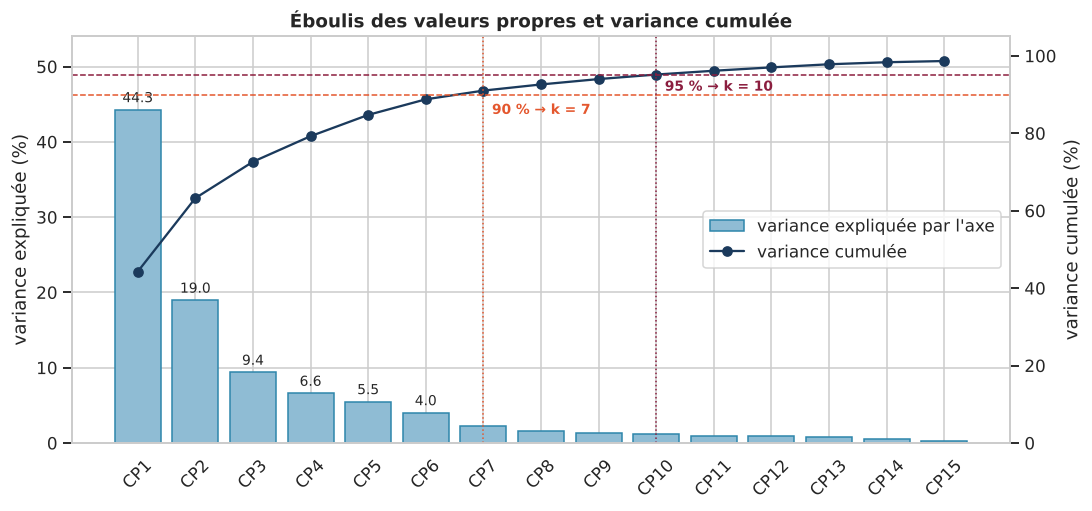

In [6]:
k90, k95 = pca.n_components_for(0.90), pca.n_components_for(0.95)
k_kaiser = int((lam > 1).sum())
print(f"Seuil 90 % : k = {k90} axes  → {100 * pca.cumulative_ratio.iloc[k90 - 1]:.2f} % de la variance")
print(f"Seuil 95 % : k = {k95} axes → {100 * pca.cumulative_ratio.iloc[k95 - 1]:.2f} % de la variance")
print(f"Critère de Kaiser (λ > 1, c'est-à-dire « un axe vaut plus qu'une variable d'origine ») : {k_kaiser} axes")
print(f"Plan CP1–CP2 : {100 * pca.cumulative_ratio.iloc[1]:.2f} % de la variance")

kk = 15
fig, ax = plt.subplots(figsize=(11, 4.8))
xs = np.arange(1, kk + 1)
bars = ax.bar(xs, 100 * pca.explained_ratio[:kk], color="#8fbcd4", edgecolor="#2E86AB", label="variance expliquée par l'axe")
for xi, v in zip(xs[:6], 100 * pca.explained_ratio[:6]):
    ax.text(xi, v + 1, f"{v:.1f}", ha="center", fontsize=9)
ax2 = ax.twinx()
ax2.plot(xs, 100 * pca.cumulative_ratio[:kk], "o-", color="#1b3a5c", label="variance cumulée")
for thr, col, k in [(90, "#E4572E", k90), (95, "#8B1E3F", k95)]:
    ax2.axhline(thr, ls="--", color=col, lw=1)
    ax2.axvline(k, ls=":", color=col, lw=1)
    ax2.text(k + 0.15, thr - 5 if thr == 90 else thr - 4, f"{thr} % → k = {k}", color=col, fontsize=9, fontweight="bold")
ax.set_xticks(xs); ax.set_xticklabels([f"CP{i}" for i in xs], rotation=45)
ax.set_ylim(0, 54); ax.set_ylabel("variance expliquée (%)"); ax2.set_ylabel("variance cumulée (%)"); ax2.set_ylim(0, 105); ax2.grid(False)
ax.set_title("Éboulis des valeurs propres et variance cumulée")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="center right")
plt.savefig(FIG / "f09_eboulis_variance.png"); plt.show()

### 3.2 Lecture et décision

- **CP1 explique 44,3 %** de la variance totale, à elle seule. C'est l'équivalent de **13,3 variables d'origine** ($\lambda_1 = 13{,}28$). C'est la signature de la forte redondance mise en évidence au notebook 01.
- **CP1 + CP2 = 63,2 %**. Le plan principal est une **bonne représentation visuelle**, mais il **perd plus d'un tiers** de la variance : il ne faut pas y lire tous les détails.
- **Seuil de 90 % → 7 axes (91,0 %)**. **Seuil de 95 % → 10 axes (95,2 %)**.
- Le **critère de Kaiser** donne 6 axes : au-delà de CP6, chaque axe explique moins qu'une seule variable d'origine.
- Le **coude** de l'éboulis apparaît après CP3 : la variance ajoutée par chaque axe passe alors sous 7 %.

**Réponse à la question du sujet.** Il faut **7 composantes pour conserver 90 %** de la variance et **10 composantes pour 95 %**. On passe donc de **30 variables corrélées à 7–10 variables non corrélées**, soit une réduction de dimension d'un facteur 3 à 4.

> ⚠️ **Piège du cours.** « 91 % de variance conservée » ne veut **pas** dire « 91 % de précision diagnostique ». C'est une part de **variance géométrique** des 30 variables standardisées. Le bon nombre d'axes pour **visualiser** (2) n'est pas forcément le bon nombre pour **prédire** : on le vérifie au § 7.

## 4. Interpréter les axes : cercle des corrélations, contributions, cos²

### 4.1 Corrélations variables–axes

Pour une ACP normée, la corrélation entre la variable $j$ et la composante $k$ vaut (démonstration dans le cours) :

$$\operatorname{Corr}(Z_j, CP_k) = u_{jk}\,\sqrt{\lambda_k}$$

Ce sont les **coordonnées des flèches** du cercle des corrélations. Attention : une corrélation n'est **pas** un coefficient de vecteur propre.

In [7]:
L = pca.loadings
# Vérification indépendante : corrélation calculée directement entre X_j et les scores
direct = pd.DataFrame({k: X.corrwith(F[k]) for k in ["CP1", "CP2", "CP3"]})
print("u_jk √λ_k == corrélation directe ?", np.allclose(direct, L[["CP1", "CP2", "CP3"]]))
L[["CP1", "CP2", "CP3"]].sort_values("CP1", ascending=False).round(3)

u_jk √λ_k == corrélation directe ? True


,CP1,CP2,CP3
concave points_mean,0.951,-0.083,-0.043
concavity_mean,0.942,0.144,0.005
concave points_worst,0.914,-0.02,-0.286
compactness_mean,0.872,0.362,-0.124
perimeter_worst,0.862,-0.477,-0.081
concavity_worst,0.834,0.234,-0.291
radius_worst,0.831,-0.525,-0.08
perimeter_mean,0.829,-0.513,-0.016
area_worst,0.82,-0.523,-0.02
area_mean,0.805,-0.551,0.048


### 4.2 Le cercle des corrélations (plan CP1–CP2)

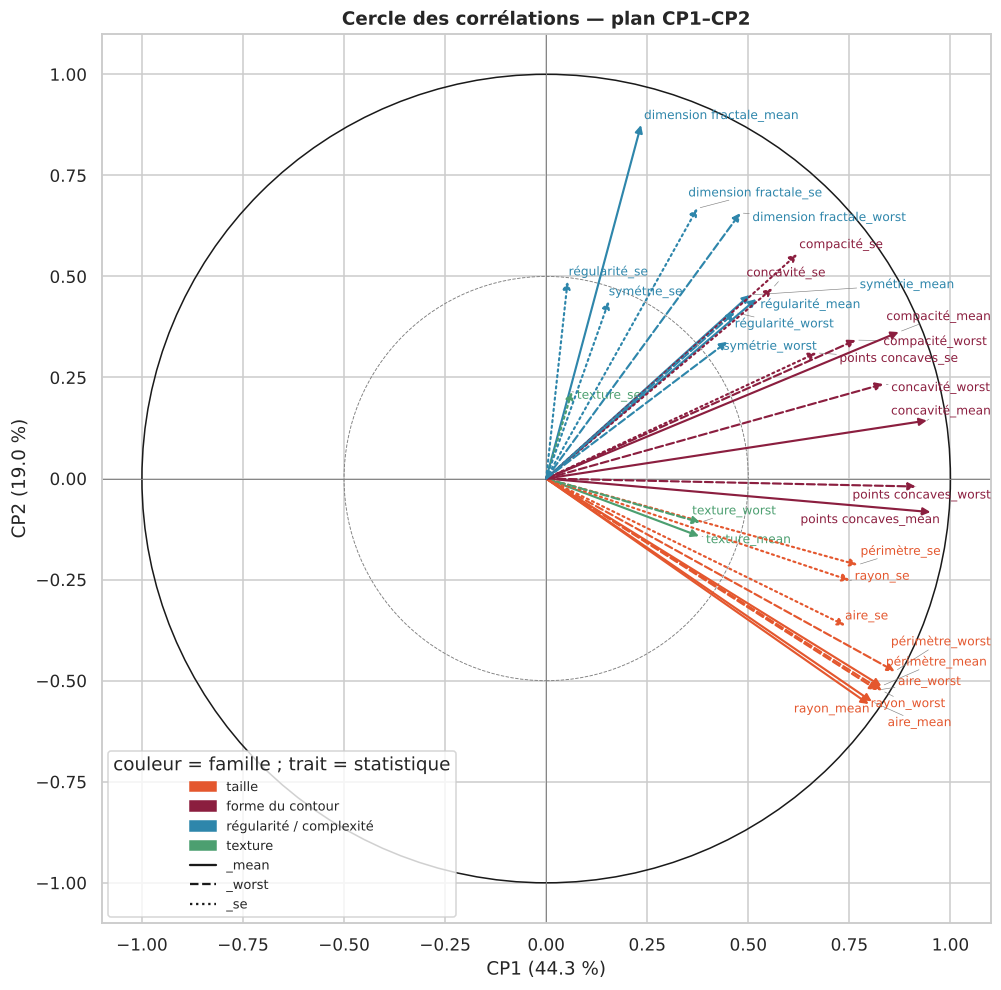

In [8]:
measure_family = {"radius": "taille", "perimeter": "taille", "area": "taille",
                  "concavity": "forme du contour", "concave points": "forme du contour", "compactness": "forme du contour",
                  "smoothness": "régularité / complexité", "fractal_dimension": "régularité / complexité", "symmetry": "régularité / complexité",
                  "texture": "texture"}
fam_col = {"taille": "#E4572E", "forme du contour": "#8B1E3F", "régularité / complexité": "#2E86AB", "texture": "#4C9F70"}
stat_ls = {"mean": "-", "worst": "--", "se": ":"}

def short(v):
    m, s = v.rsplit("_", 1)
    return f"{pp.MEASURES_FR[m]}_{s}"

fig, ax = plt.subplots(figsize=(10.5, 10.5))
ax.add_patch(Circle((0, 0), 1, fill=False, color="k", lw=1))
ax.add_patch(Circle((0, 0), 0.5, fill=False, color="grey", lw=0.6, ls="--"))
ax.axhline(0, color="grey", lw=0.6); ax.axvline(0, color="grey", lw=0.6)
texts = []
for v in X.columns:
    m, s = v.rsplit("_", 1)
    c = fam_col[measure_family[m]]
    x1, y1 = L.loc[v, "CP1"], L.loc[v, "CP2"]
    ax.annotate("", xy=(x1, y1), xytext=(0, 0),
                arrowprops=dict(arrowstyle="-|>", color=c, lw=1.4, ls=stat_ls[s], shrinkA=0, shrinkB=0))
    texts.append(ax.text(x1, y1, short(v), color=c, fontsize=8))
ev = 100 * pca.explained_ratio
ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1); ax.set_aspect("equal")
from adjustText import adjust_text
adjust_text(texts, ax=ax, expand=(1.15, 1.4), arrowprops=dict(arrowstyle="-", color="grey", lw=0.4))
ax.set_xlabel(f"CP1 ({ev['CP1']:.1f} %)"); ax.set_ylabel(f"CP2 ({ev['CP2']:.1f} %)")
ax.set_title("Cercle des corrélations — plan CP1–CP2")
handles = [Patch(color=c, label=f) for f, c in fam_col.items()] + \
          [Line2D([0], [0], color="k", ls=ls, label=f"_{s}") for s, ls in stat_ls.items()]
ax.legend(handles=handles, loc="lower left", fontsize=8.5, title="couleur = famille ; trait = statistique")
plt.savefig(FIG / "f10_cercle_correlations.png"); plt.show()

### 4.3 Contributions des variables aux axes

La **contribution** d'une variable à un axe est la part de cet axe qu'elle « construit » : $\text{ctr}_{jk} = 100\,u_{jk}^2$ (%). Comme $\sum_j u_{jk}^2 = 1$, les contributions d'un axe somment à 100 %. On compare chaque contribution à la **contribution moyenne** $100/30 \approx 3{,}33\,\%$ : une variable au-dessus de ce seuil contribue **plus que la moyenne** à l'axe.

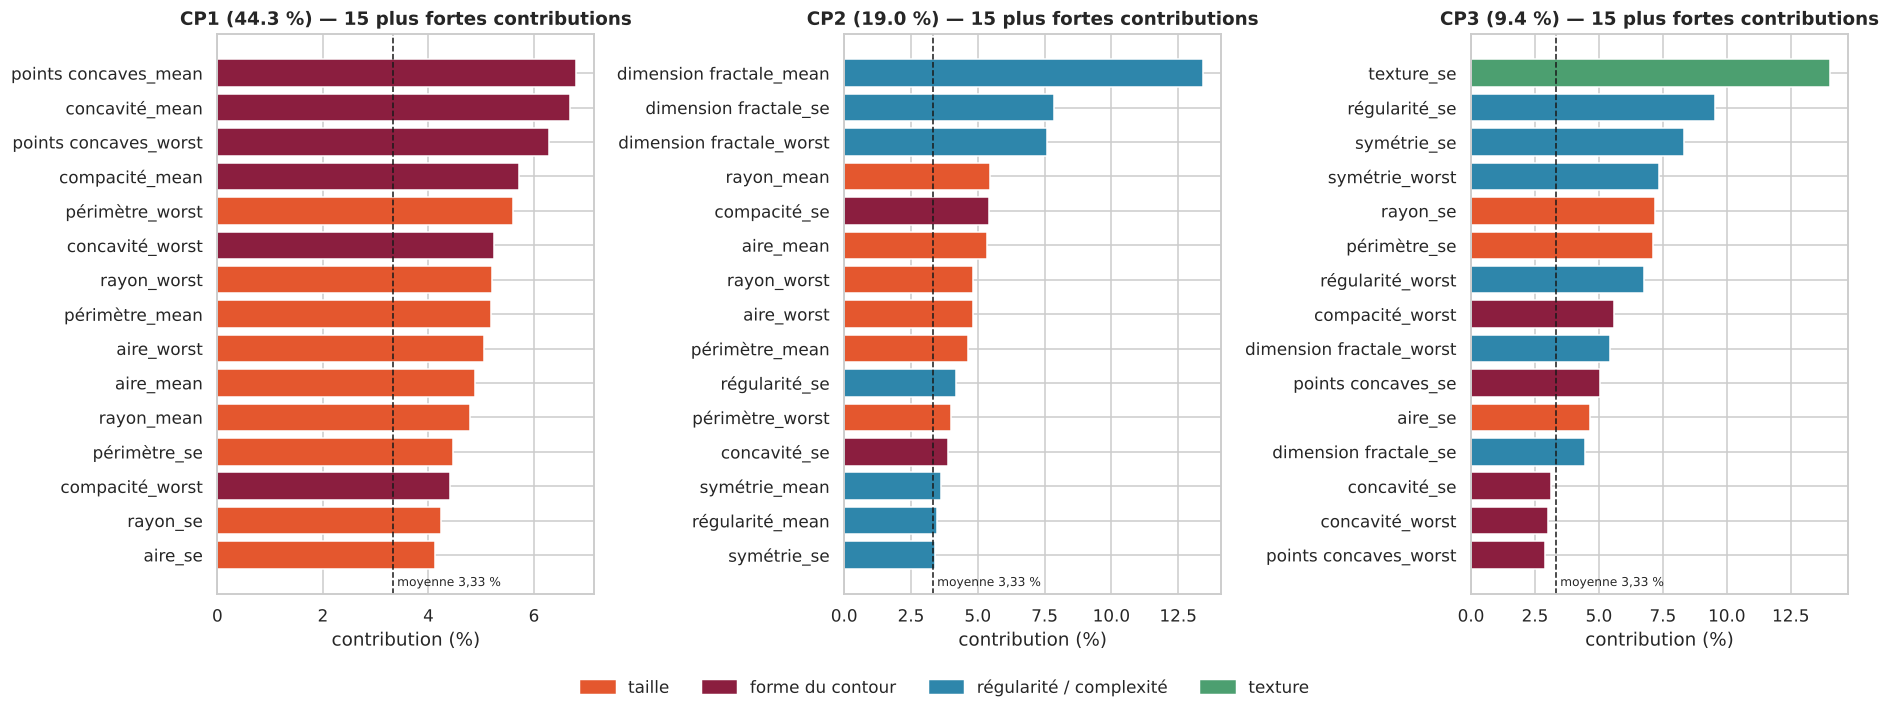

Nombre de variables au-dessus de la contribution moyenne :
CP1    16
CP2    15
CP3    12

Somme des contributions des 10 premières variables de CP1 : 56.7 %


In [9]:
ctr = pca.contributions
seuil = 100 / p
fig, axes = plt.subplots(1, 3, figsize=(17, 6.5))
for ax, k in zip(axes, ["CP1", "CP2", "CP3"]):
    s = ctr[k].sort_values(ascending=True).tail(15)
    cols = [fam_col[measure_family[v.rsplit("_", 1)[0]]] for v in s.index]
    ax.barh([short(v) for v in s.index], s.values, color=cols)
    ax.axvline(seuil, ls="--", color="k", lw=1)
    ax.text(seuil, -0.9, " moyenne 3,33 %", fontsize=8)
    ax.set_title(f"{k} ({ev[k]:.1f} %) — 15 plus fortes contributions")
    ax.set_xlabel("contribution (%)")
plt.tight_layout(rect=(0, 0.06, 1, 1))
fig.legend(handles=[Patch(color=c, label=f) for f, c in fam_col.items()], loc="lower center", ncol=4, frameon=False)
plt.savefig(FIG / "f11_contributions.png"); plt.show()

print("Nombre de variables au-dessus de la contribution moyenne :")
print((ctr[["CP1", "CP2", "CP3"]] > seuil).sum().to_string())
print(f"\nSomme des contributions des 10 premières variables de CP1 : {ctr['CP1'].sort_values(ascending=False).head(10).sum():.1f} %")

### 4.4 Interprétation des axes

**CP1 (44,3 %) — un axe « taille et irrégularité du contour ».**

- **Toutes** les corrélations avec CP1 sont **positives**. On appelle cela un **effet taille** en ACP : CP1 mesure un « niveau général » d'anomalie du noyau.
- Les variables qui **dominent** CP1 (corrélation > 0,9, contributions les plus fortes, ≈ 6–7 % chacune) sont celles de **forme du contour** : `concave points_mean` (r = 0,95), `concavity_mean` (0,94), `concave points_worst` (0,91), puis `compactness_mean`.
- Les variables de **taille** (rayon, périmètre, aire, en `mean` et `worst`) suivent de près (r ≈ 0,80–0,86, contributions ≈ 5 %).
- La **texture** (r ≈ 0,38), la **symétrie** et la **dimension fractale** y contribuent peu.

Une patiente à **droite** sur CP1 a des noyaux **grands**, aux contours **creusés** et **irréguliers**.

**Réponse à la question du sujet : l'axe 1 est dominé par les variables de concavité (points concaves, concavité, compacité) et de taille (périmètre, rayon, aire).** Ce sont aussi les variables les plus liées au diagnostic (notebook 01, § 5), ce qui annonce une bonne séparation des classes sur CP1.

**CP2 (19,0 %) — un axe « taille contre complexité fine du contour ».**

- Côté **négatif** : les variables de **taille** (rayon, aire, périmètre : r ≈ −0,48 à −0,56).
- Côté **positif** : la **dimension fractale** (`fractal_dimension_mean` : r = 0,88, `_se` et `_worst` ≈ 0,66), puis `compactness_se`, `smoothness`, `symmetry`.
- CP2 **oppose** donc les noyaux **grands** aux noyaux **petits mais au contour finement découpé**. Il apporte une information **indépendante** de CP1 (axes orthogonaux).

**CP3 (9,4 %) — un axe « variabilité entre noyaux ».** Il est porté par les **erreurs standards** (`texture_se` r = 0,63, `smoothness_se` 0,52, `symmetry_se` 0,48), opposées aux formes `worst` (`symmetry_worst` −0,46). Il décrit l'**hétérogénéité** des noyaux au sein d'une même image.

### 4.5 Qualité de représentation des variables (cos²)

Le cos² d'une variable sur le plan CP1–CP2 vaut $\operatorname{Corr}(Z_j, CP1)^2 + \operatorname{Corr}(Z_j, CP2)^2$. Il est égal au **carré de la longueur de sa flèche**. Une flèche courte (cos² faible) signifie que la variable est **mal représentée** dans le plan : on ne doit **pas** interpréter sa position ni ses angles.

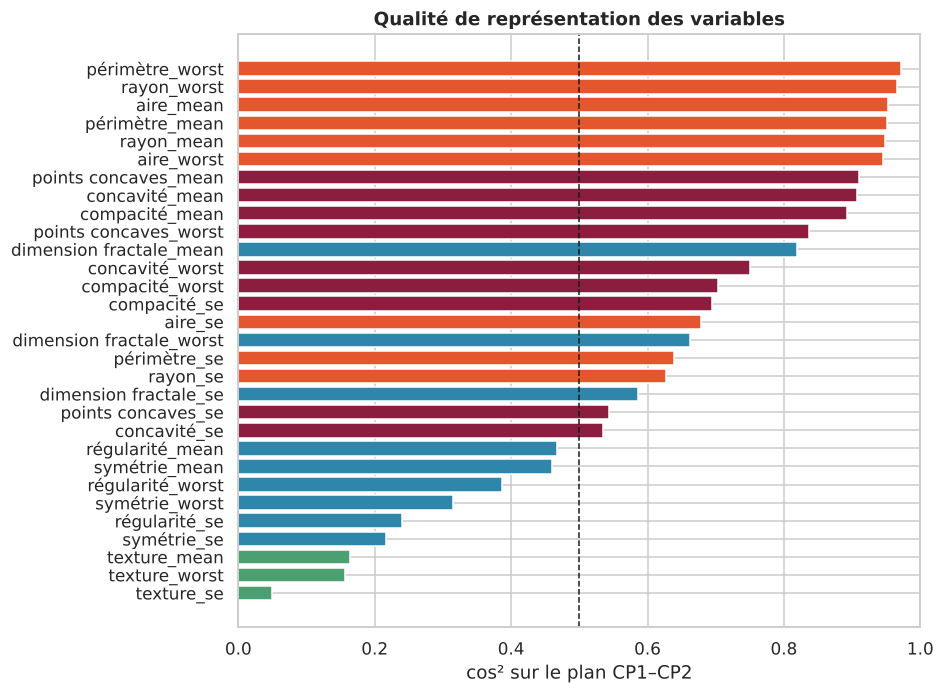

Variables mal représentées (cos² < 0,5) :
texture_se         0.05
texture_worst      0.16
texture_mean       0.16
symmetry_se        0.22
smoothness_se      0.24
symmetry_worst     0.32
smoothness_worst   0.39
symmetry_mean      0.46
smoothness_mean    0.47


In [10]:
cos2 = pca.cos2_variables(2).sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh([short(v) for v in cos2.index], cos2.values,
        color=[fam_col[measure_family[v.rsplit("_", 1)[0]]] for v in cos2.index])
ax.axvline(0.5, ls="--", color="k", lw=1); ax.set_xlim(0, 1)
ax.set_xlabel("cos² sur le plan CP1–CP2"); ax.set_title("Qualité de représentation des variables")
plt.savefig(FIG / "f12_cos2_variables.png"); plt.show()
print("Variables mal représentées (cos² < 0,5) :")
print(cos2[cos2 < 0.5].round(2).to_string())

**Lecture.** Les variables de taille et de concavité sont **bien représentées** (cos² > 0,8 ; jusqu'à 0,97 pour `perimeter_worst`) : leurs flèches touchent presque le cercle. En revanche, la **texture** (cos² ≈ 0,16), `texture_se` (0,05), `symmetry_se`, `smoothness_se` et `symmetry_worst` sont **mal représentées** sur ce plan. Leur information se trouve sur **d'autres axes** (CP3 notamment). Il ne faut donc pas conclure, par exemple, que la texture est « non corrélée » aux autres variables simplement parce que sa flèche est courte.

**Lien avec les angles.** Pour les variables bien représentées, les angles se lisent comme des corrélations : les flèches rayon, périmètre et aire sont **superposées** (r ≈ 0,99, notebook 01) ; elles forment un angle d'environ 110° avec `fractal_dimension_mean`, ce qui correspond à une corrélation **légèrement négative** (r ≈ −0,31 avec le rayon, notebook 01).

## 5. Projection des patientes : le plan factoriel

Chaque point est **une patiente**, placée selon ses scores $F = ZU$ sur CP1 et CP2. La couleur (diagnostic) est ajoutée **après** le calcul : l'ACP ne l'a jamais vue. Les ellipses contiennent environ 95 % de chaque classe (si la loi était normale).

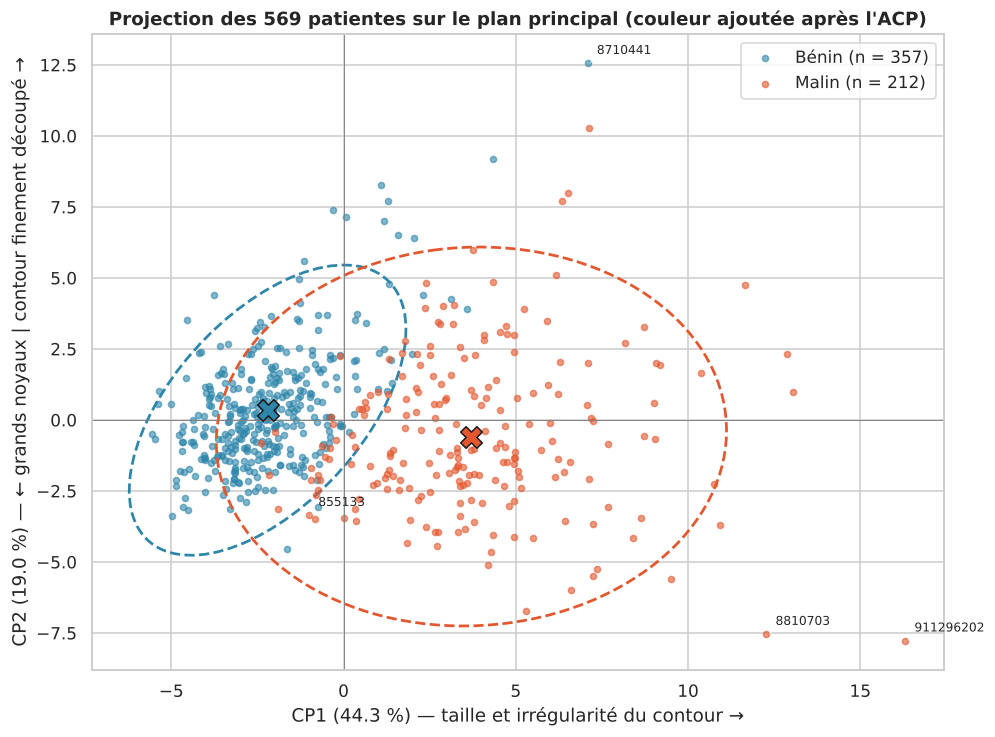

In [11]:
def ellipse(ax, pts, color, nstd=2.4477):   # 2,4477 = √χ²(2 ; 0,95)
    cov = np.cov(pts.T); vals, vecs = np.linalg.eigh(cov); o = vals.argsort()[::-1]
    vals, vecs = vals[o], vecs[:, o]; ang = np.degrees(np.arctan2(*vecs[:, 0][::-1]))
    ax.add_patch(Ellipse(pts.mean(axis=0), 2 * nstd * np.sqrt(vals[0]), 2 * nstd * np.sqrt(vals[1]),
                         angle=ang, fill=False, color=color, lw=1.8, ls="--"))

fig, ax = plt.subplots(figsize=(10, 7.5))
for lab, nom in [("B", "Bénin"), ("M", "Malin")]:
    msk = df["diagnosis"] == lab
    ax.scatter(F.loc[msk, "CP1"], F.loc[msk, "CP2"], s=16, alpha=0.6, color=PALETTE[lab], label=f"{nom} (n = {msk.sum()})")
    ellipse(ax, F.loc[msk, ["CP1", "CP2"]].values, PALETTE[lab])
    c = F.loc[msk, ["CP1", "CP2"]].mean()
    ax.scatter(*c, marker="X", s=200, color=PALETTE[lab], edgecolor="k", zorder=5)
for pid in [8810703, 911296202, 8710441, 855133]:
    ax.annotate(str(pid), F.loc[pid, ["CP1", "CP2"]], xytext=(6, 6), textcoords="offset points", fontsize=8,
                arrowprops=dict(arrowstyle="-", lw=0.6))
ax.axhline(0, color="grey", lw=0.6); ax.axvline(0, color="grey", lw=0.6)
ax.set_xlabel(f"CP1 ({ev['CP1']:.1f} %) — taille et irrégularité du contour →")
ax.set_ylabel(f"CP2 ({ev['CP2']:.1f} %) — ← grands noyaux | contour finement découpé →")
ax.set_title("Projection des 569 patientes sur le plan principal (couleur ajoutée après l'ACP)")
ax.legend(loc="upper right")
plt.savefig(FIG / "f13_plan_factoriel.png"); plt.show()

### 5.1 Quantifier ce que l'on voit

Une impression visuelle ne suffit pas. Pour chaque composante, on mesure son lien avec le diagnostic par l'**AUC** (0,5 = aucune séparation ; 1 = séparation parfaite) et par la corrélation point-bisériale.

In [12]:
sep = pd.DataFrame({
    "variance expliquée (%)": 100 * pca.explained_ratio[:8],
    "corrélation avec le diagnostic": [np.corrcoef(F[k], y)[0, 1] for k in F.columns[:8]],
    "AUC (sens indifférent)": [max(a, 1 - a) for a in (roc_auc_score(y, F[k]) for k in F.columns[:8])],
})
sep.round(3)

,variance expliquée (%),corrélation avec le diagnostic,AUC (sens indifférent)
CP1,44.27,0.785,0.97
CP2,18.97,-0.188,0.622
CP3,9.393,-0.165,0.619
CP4,6.602,0.128,0.599
CP5,5.496,0.099,0.553
CP6,4.025,-0.011,0.549
CP7,2.251,-0.078,0.575
CP8,1.589,0.064,0.546


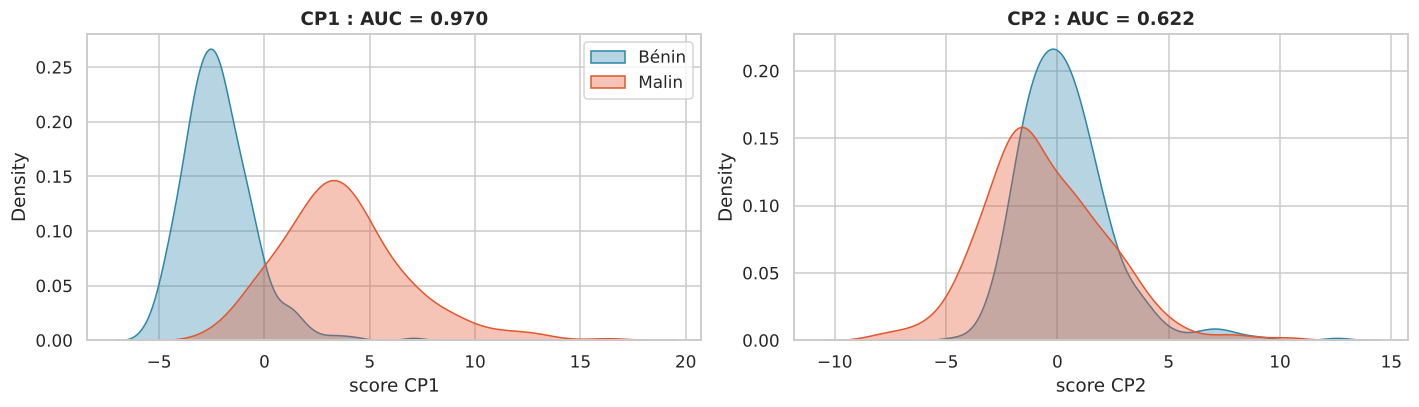

AUC de CP1 seule : 0.970  (meilleure variable d'origine seule : perimeter_worst, AUC = 0.975)


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, k in zip(axes, ["CP1", "CP2"]):
    for lab, nom in [("B", "Bénin"), ("M", "Malin")]:
        sns.kdeplot(F.loc[df["diagnosis"] == lab, k], ax=ax, fill=True, alpha=0.35, color=PALETTE[lab], label=nom)
    ax.set_title(f"{k} : AUC = {sep.loc[k, 'AUC (sens indifférent)']:.3f}"); ax.set_xlabel(f"score {k}")
axes[0].legend()
plt.tight_layout(); plt.savefig(FIG / "f14_separation_cp1_cp2.png"); plt.show()

best_var = 0.975  # AUC univariée maximale (perimeter_worst), notebook 01
print(f"AUC de CP1 seule : {sep.loc['CP1', 'AUC (sens indifférent)']:.3f}  (meilleure variable d'origine seule : perimeter_worst, AUC = {best_var})")

**Lecture.**

- **Les deux classes se séparent surtout le long de CP1.** Les tumeurs bénignes forment un nuage **compact** à gauche ; les malignes s'étalent vers la **droite**. L'AUC de CP1 vaut **0,97** : une tumeur maligne tirée au hasard a un score CP1 plus élevé qu'une bénigne dans 97 % des cas.
- **CP2 sépare peu** (AUC ≈ 0,62), et CP3 non plus. Pourtant CP2 explique **19 %** de la variance. C'est l'illustration parfaite du principe du cours : **forte variance ≠ forte importance prédictive**.
- Les malignes sont beaucoup plus **dispersées** que les bénignes (ellipse rouge bien plus grande). Médicalement, c'est cohérent : les tumeurs malignes sont **hétérogènes**, tandis que les bénignes se ressemblent.
- Il existe une **zone de recouvrement** autour de CP1 ≈ 0 : des tumeurs malignes de petite taille, au contour peu irrégulier, sont projetées au milieu des bénignes. Ce sont les cas les plus à risque de **faux négatifs** pour la suite du projet.
- Les patientes extrêmes repérées au notebook 01 (`8810703`, `911296202`) sont à l'extrême droite : ce sont de **très grandes tumeurs malignes**, cohérentes avec l'interprétation de CP1.

**Nuance importante.** L'AUC de CP1 (0,970) est du même ordre que celle de la meilleure variable seule (`perimeter_worst`, 0,975). L'ACP ne « crée » pas de pouvoir discriminant : elle **résume** en un seul axe ce que plusieurs variables corrélées disaient déjà. Si l'objectif est de **séparer** les classes, c'est l'**analyse discriminante** (supervisée) qui cherche explicitement la meilleure direction ; c'est la partie suivante du projet.

## 6. Robustesse : l'ACP dépend-elle des points extrêmes ?

Le cours prévient : l'ACP est **sensible aux valeurs extrêmes**, car la variance élève les écarts au carré. Un seul point peut faire **pivoter** CP1. Dans le notebook 01, on a décidé de **conserver** tous les outliers (informatifs). On vérifie maintenant que cette décision ne change **pas** les conclusions.

On refait l'ACP dans quatre situations et on compare :
- les pourcentages de variance et le nombre d'axes pour 90 % / 95 % ;
- l'**angle** entre les nouveaux axes CP1, CP2 et ceux de l'ACP de référence (0° = axe identique).

In [14]:
d2 = pp.robust_mahalanobis(Z)
extremes = d2.sort_values(ascending=False).index
scenarios = {
    "Référence (569 patientes)": X,
    "Sans les 2 lignes `worst = mean`": X.drop(index=df.index[df["flag_worst_eq_mean"]]),
    "Sans les 1 % les plus extrêmes (6)": X.drop(index=extremes[:6]),
    "Sans les 5 % les plus extrêmes (29)": X.drop(index=extremes[:29]),
    "Transformation log(1 + x) avant Z-score": np.log1p(X),
}
rows = []
for nom, Xa in scenarios.items():
    r = pa.fit_pca(Xa)
    rows.append({"scénario": nom, "n": len(Xa),
                 "CP1 (%)": 100 * r.explained_ratio["CP1"], "CP2 (%)": 100 * r.explained_ratio["CP2"],
                 "k (90 %)": r.n_components_for(0.90), "k (95 %)": r.n_components_for(0.95),
                 "angle CP1 (°)": pa.angle_between(pca.U["CP1"].values, r.U["CP1"].values),
                 "angle CP2 (°)": pa.angle_between(pca.U["CP2"].values, r.U["CP2"].values)})
robust = pd.DataFrame(rows).set_index("scénario")
robust.round(2)

,n,CP1 (%),CP2 (%),k (90 %),k (95 %),angle CP1 (°),angle CP2 (°)
scénario,,,,,,,
Référence (569 patientes),569,44.27,18.97,7,10,0,0
Sans les 2 lignes `worst = mean`,567,44.95,18.93,7,10,0.88,2.21
Sans les 1 % les plus extrêmes (6),563,45.42,18.64,7,10,1.77,2.7
Sans les 5 % les plus extrêmes (29),540,44.54,19.01,7,10,2.89,3.85
Transformation log(1 + x) avant Z-score,569,45.08,19.44,7,10,1.76,4.93


**Lecture et décision.**

- Dans **tous** les scénarios, CP1 explique 44,3–45,4 % de la variance, et il faut toujours **7 axes pour 90 %** et **10 axes pour 95 %**.
- CP1 ne **pivote** que de **1 à 3°**, CP2 de **2 à 5°**. Les axes et donc leur **interprétation sont inchangés**.
- Retirer les 2 lignes incohérentes (`worst = mean`) ne change pratiquement rien (CP1 tourne de moins de 1°).

**Conclusion.** Nos résultats sont **robustes**. La décision du notebook 01 (conserver tous les points) est donc validée : les valeurs extrêmes, majoritairement malignes, ne déforment pas la structure principale ; elles en font partie. La transformation log donne une ACP presque identique : il n'est pas nécessaire de l'adopter.

## 7. Ouverture : combien d'axes pour **prédire** ? (méthode C du cours)

Le cours distingue trois méthodes pour choisir $k$ : un **seuil de variance** (§ 3), le **coude** (§ 3), et la **performance du modèle** si l'objectif final est la classification. On applique la troisième, **sans fuite de données** : le Z-score **et** l'ACP sont placés **dans le pipeline**, donc réajustés sur chaque fold d'entraînement.

Le classifieur (régression logistique) sert seulement d'**outil de mesure** pour comparer les valeurs de $k$ ; le choix et l'évaluation des classifieurs relèvent de la partie « discrimination supervisée ».

In [15]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
ks = [1, 2, 3, 5, 6, 7, 10, 15, 30]
res = []
for k in ks:
    model = make_pipeline(StandardScaler(), PCA(n_components=k), LogisticRegression(max_iter=5000))
    s = cross_validate(model, X, y, cv=cv, scoring=["accuracy", "recall", "roc_auc"])
    res.append({"k": k, "variance cumulée (%)": 100 * pca.cumulative_ratio.iloc[k - 1],
                "accuracy": s["test_accuracy"].mean(), "± acc": s["test_accuracy"].std(),
                "rappel (malins)": s["test_recall"].mean(), "± rappel": s["test_recall"].std(),
                "AUC": s["test_roc_auc"].mean()})
perf = pd.DataFrame(res).set_index("k")
perf.round(3)

,variance cumulée (%),accuracy,± acc,rappel (malins),± rappel,AUC
k,,,,,,
1,44.27,0.912,0.032,0.853,0.072,0.97
2,63.24,0.949,0.024,0.919,0.064,0.99
3,72.64,0.949,0.035,0.929,0.083,0.992
5,84.73,0.963,0.024,0.948,0.058,0.994
6,88.76,0.968,0.022,0.958,0.054,0.994
7,91.01,0.968,0.026,0.953,0.067,0.994
10,95.16,0.979,0.017,0.962,0.047,0.995
15,98.65,0.979,0.017,0.957,0.054,0.995
30,100,0.975,0.02,0.953,0.052,0.995


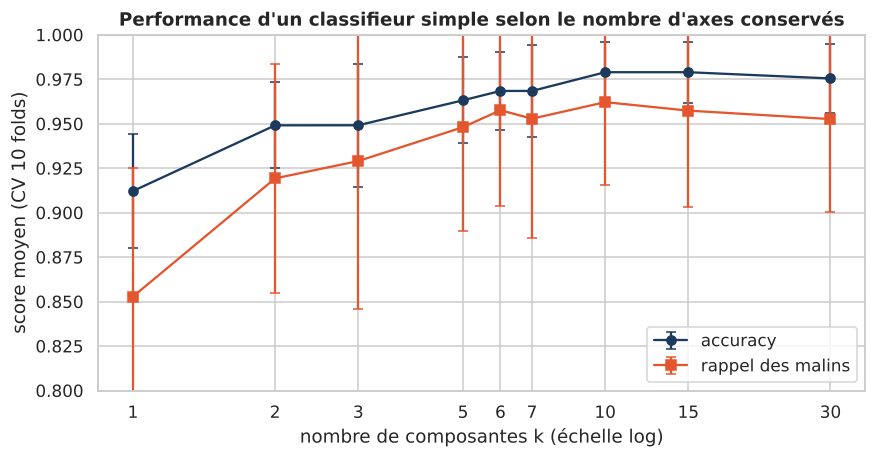

In [16]:
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.errorbar(perf.index, perf["accuracy"], yerr=perf["± acc"], fmt="o-", color="#1b3a5c", capsize=3, label="accuracy")
ax.errorbar(perf.index, perf["rappel (malins)"], yerr=perf["± rappel"], fmt="s-", color=COL_M, capsize=3, label="rappel des malins")
ax.set_xscale("log"); ax.set_xticks(ks); ax.set_xticklabels(ks)
ax.set_xlabel("nombre de composantes k (échelle log)"); ax.set_ylabel("score moyen (CV 10 folds)")
ax.set_ylim(0.8, 1.0); ax.legend(loc="lower right")
ax.set_title("Performance d'un classifieur simple selon le nombre d'axes conservés")
plt.savefig(FIG / "f15_k_performance.png"); plt.show()

**Lecture.**

- Avec **2 axes seulement**, un classifieur linéaire atteint déjà ≈ 95 % d'accuracy. La séparation bénin/malin est donc **en grande partie présente dans le plan principal**, et surtout sur CP1.
- Les performances **plafonnent autour de 5–10 axes** (≈ 96–98 % d'accuracy, AUC ≈ 0,99). Ajouter les 20 axes restants n'apporte **rien de significatif** : les écarts sont inférieurs à l'écart-type entre folds.
- Le choix « 7 axes = 90 % » ou « 10 axes = 95 % » est donc **cohérent avec l'objectif de prédiction** : on divise la dimension par 3 à 4 sans perte mesurable.

**Intérêt pour la suite du projet.** Travailler sur 7 à 10 composantes **non corrélées** règle aussi le problème signalé au notebook 01 : la matrice de covariance des 30 variables brutes est presque non inversible (conditionnement ≈ 10⁵), alors que celle des composantes est **diagonale**. C'est une option solide pour la distance de **Mahalanobis** et l'**ADL**.

## 8. Projeter un nouveau cas (pour le dashboard)

Pour une nouvelle patiente, on **ne recalcule pas** l'ACP. On la centre-réduit avec les **moyennes et écarts-types appris**, puis on la multiplie par la **même** matrice $U$ : $F_{\text{nouveau}} = Z_{\text{nouveau}}\,U$. C'est ce que fait `PCAResult.transform`.

In [17]:
nouveau = X.loc[[842302]]                    # exemple : on fait comme si cette patiente arrivait
print("Coordonnées via transform :", pca.transform(nouveau)[["CP1", "CP2"]].round(3).values)
print("Coordonnées dans F        :", F.loc[[842302], ["CP1", "CP2"]].round(3).values)

Coordonnées via transform : [[9.185 1.947]]
Coordonnées dans F        : [[9.185 1.947]]


In [18]:
out = ROOT / "data" / "processed"
F.iloc[:, :10].assign(diagnosis=df["diagnosis"]).to_csv(out / "pca_scores.csv")
L.to_csv(out / "pca_correlations_variables.csv")
pca.U.to_csv(out / "pca_vecteurs_propres.csv")
tab.to_csv(out / "pca_valeurs_propres.csv")
pd.DataFrame({"mean": pca.mean, "std": pca.std}).to_csv(out / "pca_parametres_standardisation.csv")
print("Exports pour le dashboard :", sorted(p.name for p in out.glob("pca_*.csv")))

Exports pour le dashboard : ['pca_correlations_variables.csv', 'pca_parametres_standardisation.csv', 'pca_scores.csv', 'pca_valeurs_propres.csv', 'pca_vecteurs_propres.csv']


## 9. Conclusions de l'ACP

| Question | Réponse | Preuve |
|---|---|---|
| Faut-il réduire les variables ? | **Oui** | Sans réduction, CP1 = 98 % de variance et ≈ 99,6 % d'aire (notebook 01, § 8) |
| Combien d'axes pour 90 % ? | **7 axes** (91,0 %) | Variance cumulée, § 3 |
| Combien d'axes pour 95 % ? | **10 axes** (95,2 %) | Variance cumulée, § 3 |
| Que représente l'axe 1 ? | **Taille et irrégularité du contour** (effet taille) | Toutes les corrélations positives ; § 4 |
| Quelles variables dominent l'axe 1 ? | **Points concaves, concavité, compacité**, puis **périmètre, rayon, aire** | Corrélations 0,80–0,95 ; contributions 5–7 % (moyenne 3,3 %) |
| Que représente l'axe 2 ? | **Taille vs complexité fine du contour** (dimension fractale) | § 4.4 |
| Le diagnostic apparaît-il ? | **Oui, surtout sur CP1** (AUC = 0,97) ; CP2 sépare peu | § 5 |
| Les résultats sont-ils robustes ? | **Oui** : CP1 pivote de moins de 3° sans les extrêmes ou après log | § 6 |
| Combien d'axes pour prédire ? | Performances stables dès **5–10 axes** | Validation croisée sans fuite, § 7 |

**Message pour la soutenance.** *Les 30 mesures se résument essentiellement à quelques dimensions. La première, qui concentre 44 % de la variance, décrit la taille des noyaux et l'irrégularité de leur contour. Construite sans connaître le diagnostic, elle sépare déjà très bien les tumeurs bénignes des malignes. Il faut 7 axes pour conserver 90 % de l'information et 10 axes pour 95 %, et ces résultats ne dépendent pas des valeurs extrêmes.*

**Limites.**
- L'ACP est une méthode **linéaire** : elle ne capte pas les relations courbes (par exemple aire ∝ rayon²).
- La variance expliquée mesure une information **géométrique**, pas une information **médicale**.
- Le plan CP1–CP2 ne montre que 63 % de la variance : certaines variables (texture, symétrie) y sont mal représentées.
- Les conclusions portent sur **569 patientes d'un seul centre** : elles devraient être confirmées sur d'autres données avant tout usage clinique.